# Titanic: le domande dell'introduzione alla XAI

Notebook di accompagnamento alla nota `appunti/approfondimenti/01_introduzione_xai_titanic.md` del cookbook (lezione del 25 febbraio 2026). Quattro esperimenti brevi: una regola leggibile non è una regola validata; l'accuratezza globale nasconde i gruppi; fidelity e accuratezza di un surrogato sono numeri diversi; un surrogato globale può essere fedele ovunque tranne dove conta.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from titanic_data import load_titanic, split, Encoder, feature_table, rate_by, group_metrics, DIED, SURVIVED

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
GRAY = "#7f7f7f"

df = load_titanic()
tr, te = split(df)                      # 70/30 stratificato, random_state=0
enc = Encoder().fit(tr)                 # mediana dell'età e moda del porto dal solo training
Xtr, Xte = enc.transform(tr), enc.transform(te)
ytr, yte = tr["Survived"].values, te["Survived"].values
cols = list(Xtr.columns)
print(f"{len(df)} passeggeri, sopravvissuti {df.Survived.sum()} ({df.Survived.mean():.3f})")
print(f"training {len(tr)} (tasso {ytr.mean():.3f}) · test {len(te)} (tasso {yte.mean():.3f})")
print(f"mediana età (training) {enc.age_median} · moda porto {enc.port_mode}")

891 passeggeri, sopravvissuti 342 (0.384)
training 623 (tasso 0.384) · test 268 (tasso 0.384)
mediana età (training) 28.75 · moda porto S


## 0. Il dataset

**891 passeggeri** del Titanic (copia `titanic.csv` di Data Science Dojo, uguale al training set Kaggle; l'equipaggio non c'è). **Target** `Survived`: 1 = sopravvissuto (342, 38,4%). Escluse: `PassengerId` (identificativo), `Name` (da cui si ricava `Title`), `Ticket` (quasi un identificativo), `Cabin` (mancante nel 77%).

Codifica numerica per i modelli (`titanic_data.Encoder`): `Sex_female` 0/1; `Age` con i mancanti sostituiti dalla mediana **del training** più l'indicatore `Age_missing`; `Embarked` one-hot (`Embarked_C`, `Embarked_Q`; S è la categoria di riferimento, i 2 mancanti diventano la moda S); `Pclass`, `SibSp`, `Parch`, `Fare` come numeri.

In [2]:
display(feature_table(df))
for c in ["Sex", "Pclass", "Embarked", "Title"]:
    display(rate_by(df, c).T)
display(df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc=["size", "mean"]).round(3))

,feature,tipo,valori,mancanti
0,Pclass,ordinale,"1, 2, 3",0
1,Sex,nominale binaria,"female, male",0
2,Age,continua,"0.42–80, mediana 28",177
3,SibSp,conteggio,"0, 1, 2, 3, 4, 5, 8",0
4,Parch,conteggio,"0, 1, 2, 3, 4, 5, 6",0
5,Fare,continua,"0–512.329, mediana 14.4542",0
6,Embarked,nominale,"C, Q, S",2
7,Title,nominale (derivata),"Master, Miss, Mr, Mrs, Other",0
8,FamilySize,conteggio (derivata),"1, 2, 3, 4, 5, 6, 7, 8, 11",0


Sex,female,male
passeggeri,314.000,577.000
sopravvissuti,233.000,109.000
tasso,0.742,0.189


Pclass,1,2,3
passeggeri,216.00,184.000,491.000
sopravvissuti,136.00,87.000,119.000
tasso,0.63,0.473,0.242


Embarked,C,Q,S,mancante
passeggeri,168.000,77.00,644.000,2.0
sopravvissuti,93.000,30.00,217.000,2.0
tasso,0.554,0.39,0.337,1.0


Title,Master,Miss,Mr,Mrs,Other
passeggeri,40.000,182.000,517.000,125.000,27.000
sopravvissuti,23.000,127.000,81.000,99.000,12.000
tasso,0.575,0.698,0.157,0.792,0.444


size             mean              
Pclass    1    2    3      1      2      3
Sex                                       
female   94   76  144  0.968  0.921  0.500
male    122  108  347  0.369  0.157  0.135

## 1. Una regola leggibile: «donna → sopravvive»

La regola si calcola a mano e si contesta a mano. Leggibile non vuol dire validata: la misuriamo su training e test, e per gruppo.

In [3]:
rule = lambda d: (d["Sex"] == "female").astype(int).values
for name, d in [("training", tr), ("test", te)]:
    print(f"{name}: accuratezza regola {np.mean(rule(d) == d.Survived.values):.4f} · "
          f"classe maggioritaria (nessuno sopravvive) {1 - d.Survived.mean():.4f}")
pr = rule(te)
print("\nPer sesso (test):"); display(group_metrics(yte, pr, te.Sex.values)[["N", "TP", "FN", "FP", "TN", "TPR", "FPR", "Accuracy"]].round(3))
m = ((te.Sex == "female") & (te.Pclass == 3)).values
print(f"Donne di terza classe nel test: {m.sum()}, sopravvissute {yte[m].mean():.3f}, accuratezza della regola {np.mean(pr[m] == yte[m]):.3f}")

training: accuratezza regola 0.7849 · classe maggioritaria (nessuno sopravvive) 0.6164
test: accuratezza regola 0.7910 · classe maggioritaria (nessuno sopravvive) 0.6157

Per sesso (test):


,N,TP,FN,FP,TN,TPR,FPR,Accuracy
male,173.0,0.0,32.0,0.0,141.0,0.0,0.0,0.815
female,95.0,71.0,0.0,24.0,0.0,1.0,1.0,0.747


Donne di terza classe nel test: 48, sopravvissute 0.542, accuratezza della regola 0.542


Sugli uomini la regola ha accuratezza 0,815 senza riconoscere **nessun** sopravvissuto (TPR 0): l'accuratezza alta viene dal fatto che gli uomini muoiono quasi tutti. Sulle donne di terza classe vale quanto un lancio di moneta.

## 2. Un modello opaco e il suo surrogato: fidelity contro accuratezza

$f$ = random forest (500 alberi). $g$ = albero di profondità $d$ addestrato a imitare le **predizioni** di $f$ sul training. Fidelity = accordo di classe fra $g$ e $f$ sul test; nella formula non compare $y$. Vale $|\mathrm{Acc}(g)-\mathrm{Acc}(f)|\le 1-\mathrm{Fid}(f,g)$.

Acc(f) training 0.9117 · test 0.8396


,foglie,"Fid(f,g)",Acc(g),limite inf.,limite sup.
profondità,,,,,
1,2,0.8694,0.7910,0.7090,0.9701
2,4,0.8694,0.7910,0.7090,0.9701
3,7,0.9067,0.8134,0.7463,0.9328
4,12,0.9142,0.8134,0.7537,0.9254
5,19,0.9440,0.8433,0.7836,0.8955
6,25,0.9627,0.8396,0.8022,0.8769


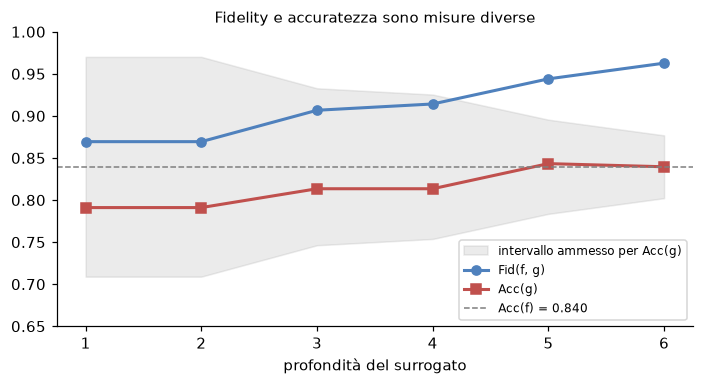

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, export_text

rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=0).fit(Xtr, ytr)
f_tr, f_te = rf.predict(Xtr), rf.predict(Xte)
acc_f = np.mean(f_te == yte)
print(f"Acc(f) training {rf.score(Xtr, ytr):.4f} · test {acc_f:.4f}")
rows = []
for d in range(1, 7):
    g = DecisionTreeClassifier(max_depth=d, random_state=0).fit(Xtr, f_tr)
    fid = np.mean(g.predict(Xte) == f_te)
    rows.append({"profondità": d, "foglie": g.get_n_leaves(), "Fid(f,g)": fid, "Acc(g)": np.mean(g.predict(Xte) == yte),
                 "limite inf.": acc_f - (1 - fid), "limite sup.": acc_f + (1 - fid)})
tab = pd.DataFrame(rows).set_index("profondità"); display(tab.round(4))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.fill_between(tab.index, tab["limite inf."], tab["limite sup."], color=GRAY, alpha=0.15, label="intervallo ammesso per Acc(g)")
ax.plot(tab.index, tab["Fid(f,g)"], "o-", color=SURVIVED, lw=2, label="Fid(f, g)")
ax.plot(tab.index, tab["Acc(g)"], "s-", color=DIED, lw=2, label="Acc(g)")
ax.axhline(acc_f, color=GRAY, lw=1, ls="--", label=f"Acc(f) = {acc_f:.3f}")
ax.set_xlabel("profondità del surrogato"); ax.set_ylim(0.65, 1.0); ax.legend(fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False); ax.set_title("Fidelity e accuratezza sono misure diverse", fontsize=10)
plt.tight_layout(); plt.show()

## 3. Dove cadono i disaccordi: fedele in media, infedele in un gruppo

Prendiamo il surrogato di profondità 3 (7 foglie) e misuriamo la fidelity per sesso × classe.

In [5]:
g3 = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr, f_tr)
print(export_text(g3, feature_names=cols))
gp = g3.predict(Xte)
grp = te.Sex.map({"female": "donne", "male": "uomini"}) + ", " + te.Pclass.astype(str) + "ª"
out = pd.DataFrame({"N": grp.value_counts()})
for k in out.index:
    mm = (grp == k).values
    out.loc[k, "Fid(f,g)"] = np.mean(gp[mm] == f_te[mm]); out.loc[k, "Acc(f)"] = np.mean(f_te[mm] == yte[mm]); out.loc[k, "Acc(g)"] = np.mean(gp[mm] == yte[mm])
print(f"Fidelity globale {np.mean(gp == f_te):.4f}"); display(out.sort_index().round(3))

|--- Sex_female <= 0.50
|   |--- Age <= 13.00
|   |   |--- SibSp <= 2.50
|   |   |   |--- class: 1
|   |   |--- SibSp >  2.50
|   |   |   |--- class: 0
|   |--- Age >  13.00
|   |   |--- Fare <= 26.14
|   |   |   |--- class: 0
|   |   |--- Fare >  26.14
|   |   |   |--- class: 0
|--- Sex_female >  0.50
|   |--- Pclass <= 2.50
|   |   |--- class: 1
|   |--- Pclass >  2.50
|   |   |--- Fare <= 7.89
|   |   |   |--- class: 1
|   |   |--- Fare >  7.89
|   |   |   |--- class: 0

Fidelity globale 0.9067


,N,"Fid(f,g)",Acc(f),Acc(g)
"donne, 1ª",26,1.000,0.962,0.962
"donne, 2ª",21,1.000,0.952,0.952
"donne, 3ª",48,0.646,0.729,0.583
"uomini, 1ª",34,0.794,0.647,0.618
"uomini, 2ª",33,1.000,0.939,0.939
"uomini, 3ª",106,0.991,0.868,0.877


La fidelity globale 0,907 è una media: sulle donne di terza classe il surrogato concorda con la foresta solo nel 64,6% dei casi. È il gruppo in cui la decisione è più incerta (§1) ed è proprio lì che il surrogato «spiega» un modello diverso da quello vero.

## 4. Proxy: togliere una feature non toglie l'informazione

`Title` codifica il sesso (Mr e Master sono solo uomini, Miss e Mrs solo donne) e `Fare` è legata alla classe.

In [6]:
display(pd.crosstab(df.Title, df.Sex))
from scipy.stats import spearmanr
print(f"Spearman(Fare, Pclass) = {spearmanr(df.Fare, df.Pclass)[0]:.3f}")

Sex,female,male
Title,,
Master,0,40
Miss,182,0
Mr,0,517
Mrs,125,0
Other,7,20


Spearman(Fare, Pclass) = -0.688
